# Analyze IMs potentially associated with the deconstruction of cellulose deeply

In [ ]:
import os
from os import path
import pandas as pd

#plotting
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

#pymodulon
import pymodulon
from pymodulon.io import *
from pymodulon.plotting import *
from pymodulon.enrichment import compute_enrichment, compute_annotation_enrichment

In [2]:
# matplotlib default font
plt.rcParams['font.family'] = 'serif'
# Specify a preferred fallback list of fonts
plt.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif']

### LOAD THE DATA

In [ ]:
data_dir = path.join('..', 'ctherm_nf','processed_data')

# load the data
ica_data = load_json_model(path.join(data_dir, 'ctherm.json.gz')) #adjusted

# Other required information from icadata object
df_metadata = ica_data.sample_table
df_expression = ica_data.X


# ### gene info
df_gene_info = pd.read_csv(path.join(data_dir, 'gene_info.csv'), index_col=0)
df_gene_info.head()

/Users/skd6150/Applications/anaconda3/envs/modulome_mac/lib/python3.9/site-packages/pymodulon/util.py:31: FutureWarning: Passing literal json to 'read_json' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  table = pd.read_json(table)
/Users/skd6150/Applications/anaconda3/envs/modulome_mac/lib/python3.9/site-packages/pymodulon/util.py:31: FutureWarning: Passing literal json to 'read_json' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  table = pd.read_json(table)
/Users/skd6150/Applications/anaconda3/envs/modulome_mac/lib/python3.9/site-packages/pymodulon/util.py:31: FutureWarning: Passing literal json to 'read_json' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  table = pd.read_json(table)
/Users/skd6150/Applications/anaconda3/envs/modulome_mac/lib/python3.9/site-packages/p

,gene_name,accession,old_locus_tag,start,end,strand,gene_product,COG,uniprot,operon,GO_MF,GO_BP,InterPro,PFAMs
locus_tag,,,,,,,,,,,,,,
Clo1313_0001,dnaA,CP002416.1,NaN,212,1543,+,chromosomal replication initiator protein DnaA,No COG annotation,UPI0001B1F046,Op0,ATP binding; DNA replication origin binding; l...,DNA replication initiation; regulation of DNA ...,AAA+_ATPase;Chromosome_initiator_DnaA;Chromoso...,NaN
Clo1313_0002,RS00015,CP002416.1,NaN,1793,2893,+,DNA polymerase III%2C beta subunit,No COG annotation,UPI00017E1F7F,Op1,NaN,NaN,DNA_clamp_sf;DNA_polIII_beta;DNA_polIII_beta_C...,NaN
Clo1313_0003,yaaA,CP002416.1,NaN,2909,3115,+,S4 domain protein YaaA,No COG annotation,UPI000038F4E6,Op1,NaN,NaN,RNA-bd_S4-rel_YaaA;S4_RNA-bd;S4_RNA-bd_sf;,NaN
Clo1313_0004,recF,CP002416.1,NaN,3133,4242,+,DNA replication and repair protein RecF,No COG annotation,UPI00003C8C54,Op1,ATP binding; single-stranded DNA binding,DNA replication; DNA synthesis involved in DNA...,DNA-binding_RecF;DNA-binding_RecF_CS;P-loop_NT...,NaN
Clo1313_0005,RS00030,CP002416.1,NaN,4410,4724,+,hypothetical protein,Function unknown,UPI000038F4E8,Op2,NaN,NaN,RemA-like;,DUF370


### First rename the imodulon

In [6]:
df_rename_imod = pd.read_csv('./results_characterize_imodulons/imod_rename_mapping.tsv', sep='\t', index_col=0)
dict_rename_imod = df_rename_imod[['IM']].to_dict()['IM']

# rename all at once
ica_data.rename_imodulons(dict_rename_imod)

# set IM as index for this work
df_rename_imod.set_index('IM', inplace=True)

# GRN for regulation in C. thermocellum
for i,row in ica_data.imodulon_table.iterrows():
    if pd.notnull(row.regulator):
        ica_data.imodulon_table.loc[i, 'category'] = 'regulatory'
    else:
        ica_data.imodulon_table.loc[i, 'category'] = df_rename_imod.loc[i, 'category']



### Analyze cellulose degradation by performing DIMA to find which IMs are associated with cellulose degradation 

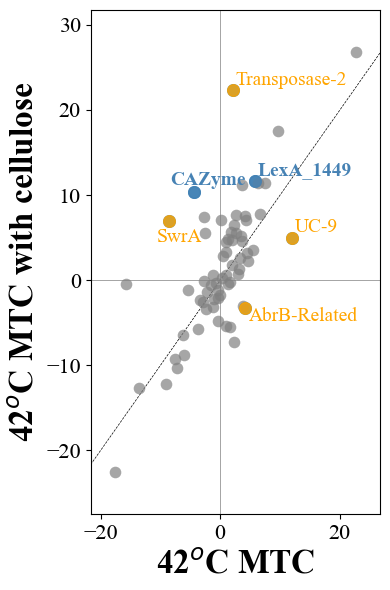

,difference,pvalue,qvalue,0,1
Transposase-2,20.233271,0.000586,0.039282,2.057051,22.290322
SwrA,15.580438,0.007133,0.079648,-8.578175,7.002263
CAZyme,14.803339,0.002715,0.060629,-4.443052,10.360287
LexA_1449,5.954712,0.004665,0.062509,5.741601,11.696313
UC-9,-7.058433,0.001550,0.051939,12.039498,4.981066
AbrB-Related,-7.489570,0.003654,0.061211,4.191336,-3.298233


In [7]:
base_condition = 'cell_stressor:42T_mtc'
diff_condition = 'cell_stressor:42T_mtc_cel'
dict_colors = {'CAZyme': 'steelblue', 'LexA_1449': 'steelblue', 'Transposase-2': 'orange', 'SwrA': 'orange', 'UC-9': 'orange', 'AbrB-Related': 'orange'}
ax, df_dima_42_42 = plot_dima(ica_data, 
                            base_condition, 
                            diff_condition, 
                            threshold=5,
                            fdr=0.1,
                            table=True,
                            scatter_kwargs = {'alpha':0.8, 's':70},
                            )


labels_of_interest = list() #any labels that I would like to keep
for t in ax.texts:
    if t.get_text() not in labels_of_interest:
        t.remove()

for imod, row in df_dima_42_42.iterrows():
    if imod in ['AbrB-Related']:
        ax.text(row[0]+0.5, row[1]-1.5,
                imod, fontsize=14, color=dict_colors[imod])
    elif imod in ['SwrA']:
        ax.text(row[0]-2., row[1]-2.5,
                imod, fontsize=14, color=dict_colors[imod])
    elif imod in ['LexA_1449']:
        ax.text(row[0] + 0.5, row[1]+0.7,
                imod, fontsize=14, fontweight='bold', color=dict_colors[imod])
    elif imod in [ 'CAZyme']:
            ax.text(row[0] - 4., row[1]+0.8,
                    imod, fontsize=14, fontweight='bold', color=dict_colors[imod])
    else:
        ax.text(row[0] + 0.5, row[1]+0.7,
                imod, fontsize=14, color=dict_colors[imod])
    
    ax.scatter(row[0], row[1], color=dict_colors[imod], alpha=0.8, s=70, zorder=10)

# set x and y labels
ax.set_xlabel(f'42$^o$C MTC', fontdict={'weight':'bold', 'size':24})
# ax.set_ylabel(f'MTC with cellulose', fontdict={'weight':'bold', 'size':20})
ax.set_ylabel(f'42$^o$C MTC with cellulose', fontdict={'weight':'bold', 'size':24})

# tick sizes
ax.tick_params(labelsize=16)

# Get current figure object and modify its size
fig = plt.gcf() 
fig.set_size_inches(4, 6)


plt.tight_layout()

# save plot
# plt.savefig('./results_characterize_imodulons/dima_42_42_cellulose.png', transparent=True, pad_inches=0.01, dpi=300, format='png')

plt.show()

df_dima_42_42

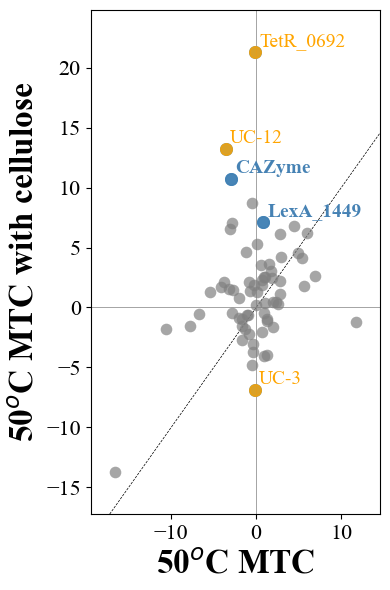

,difference,pvalue,qvalue,0,1
TetR_0692,21.436691,0.006736,0.075218,-0.103069,21.333623
UC-12,16.813458,0.001825,0.053648,-3.551357,13.262101
CAZyme,13.709942,0.003552,0.053648,-2.943995,10.765947
LexA_1449,6.270995,0.004004,0.053648,0.842289,7.113284
UC-3,-6.726064,0.003953,0.053648,-0.174518,-6.900583


In [10]:
base_condition = 'cell_stressor:50T_mtc'
diff_condition = 'cell_stressor:50T_mtc_cel'
dict_colors = {'CAZyme': 'steelblue', 'LexA_1449': 'steelblue', 'TetR_0692': 'orange', 'UC-12': 'orange', 'UC-3': 'orange'}

ax, df_dima_50_50 = plot_dima(ica_data, 
                            base_condition, 
                            diff_condition, 
                            threshold=5,
                            fdr=0.1,
                            table=True,
                            scatter_kwargs = {'alpha':0.8, 's':70},
                            )

labels_of_interest = list() #any labels that I would like to keep
for t in ax.texts:
    if t.get_text() not in labels_of_interest:
        t.remove()

for imod, row in df_dima_50_50.iterrows():
    if imod in ['CAZyme', 'LexA_1449']:
        ax.text(row[0] + 0.5, row[1]+0.5,
                imod, fontsize=14, fontweight='bold', color=dict_colors[imod])
    else:
        ax.text(row[0] + 0.5, row[1]+0.5,
                imod, fontsize=14, color=dict_colors[imod])

    ax.scatter(row[0], row[1], color=dict_colors[imod], alpha=0.8, s=70, zorder=10)


# set x and y labels
ax.set_xlabel(f'50$^o$C MTC', fontdict={'weight':'bold', 'size':24})
# ax.set_ylabel(f'')
ax.set_ylabel(f'50$^o$C MTC with cellulose', fontdict={'weight':'bold', 'size':24})

# tick sizes
ax.tick_params(labelsize=16)

# Get current figure object and modify its size
fig = plt.gcf() 
fig.set_size_inches(4, 6)


plt.tight_layout()

# save plot
# plt.savefig('./results_characterize_imodulons/dima_50_50_cellulose.png', transparent=True, pad_inches=0.01, dpi=300, format='png')

plt.show()

df_dima_50_50

In [11]:
# the genes from literature associated with cellulose deconstruction
genes_of_cellulosomes = ['Clo1313_0627', 'Clo1313_0628', 'Clo1313_0629', 'Clo1313_0630', 'Clo1313_0950', 'Clo1313_1487', 'Clo1313_1488', 'Clo1313_1768', 'Clo1313_0135', 'Clo1313_0177', 'Clo1313_0349', 'Clo1313_0350', 'Clo1313_0399', 'Clo1313_0400', 'Clo1313_0413', 'Clo1313_0420', 'Clo1313_0500', 'Clo1313_0501', 'Clo1313_0521', 'Clo1313_0563', 'Clo1313_0685', 'Clo1313_0689', 'Clo1313_0693', 'Clo1313_0849', 'Clo1313_0851', 'Clo1313_0985', 'Clo1313_0987', 'Clo1313_1305', 'Clo1313_1396', 'Clo1313_1398', 'Clo1313_1424', 'Clo1313_1425', 'Clo1313_1477', 'Clo1313_1494', 'Clo1313_1563', 'Clo1313_1564', 'Clo1313_1587', 'Clo1313_1603', 'Clo1313_1604', 'Clo1313_1659', 'Clo1313_1694', 'Clo1313_1701', 'Clo1313_1786', 'Clo1313_1788', 'Clo1313_1808', 'Clo1313_1809', 'Clo1313_1816', 'Clo1313_1955', 'Clo1313_1959', 'Clo1313_1960', 'Clo1313_1971', 'Clo1313_1983', 'Clo1313_1990', 'Clo1313_2022', 'Clo1313_2042', 'Clo1313_2043', 'Clo1313_2188', 'Clo1313_2189', 'Clo1313_2202', 'Clo1313_2216', 'Clo1313_2234', 'Clo1313_2479', 'Clo1313_2530', 'Clo1313_2564', 'Clo1313_2635', 'Clo1313_2693', 'Clo1313_2747', 'Clo1313_2793', 'Clo1313_2794', 'Clo1313_2795', 'Clo1313_2805', 'Clo1313_2843', 'Clo1313_2856', 'Clo1313_2858', 'Clo1313_2859', 'Clo1313_2860', 'Clo1313_2861', 'Clo1313_2944', 'Clo1313_3023']
free_enzymes = ['Clo1313_0133', 'Clo1313_0333', 'Clo1313_0395', 'Clo1313_0397', 'Clo1313_0436', 'Clo1313_0539', 'Clo1313_0613', 'Clo1313_0714', 'Clo1313_0820', 'Clo1313_1002', 'Clo1313_1336', 'Clo1313_1426', 'Clo1313_1904', 'Clo1313_1954', 'Clo1313_1958', 'Clo1313_2020', 'Clo1313_2161', 'Clo1313_2192', 'Clo1313_2233', 'Clo1313_2382', 'Clo1313_2450', 'Clo1313_2460', 'Clo1313_2473', 'Clo1313_2584', 'Clo1313_2777', 'Clo1313_2853', 'Clo1313_2854']

genes_of_cellulosomes.extend(free_enzymes)
genes_of_cellulosomes = list(dict.fromkeys(genes_of_cellulosomes))

# Get genes for each iModulon
dict_imodulon_genes = {im: ica_data.view_imodulon(im).index.tolist()
                  for im in ica_data.imodulon_names}

imods_of_interest = list()
# now perform enrichment
for imod, genes in dict_imodulon_genes.items():
    res = compute_enrichment(genes_of_cellulosomes, 
                             genes,
                            ica_data.gene_names)
    if res.pvalue < 0.05:
        print(imod, res.f1score, res.pvalue)
        imods_of_interest.append(imod)

    if imod=='LexA_1449':
        print(imod, res.f1score, res.pvalue)

SigI6 0.34074074074074073 2.7036028680534776e-29
CAZyme 0.34285714285714286 1.92315235623724e-28
BlaI_0696 0.06349206349206349 0.005128513872802494
LexA_1449 0 1
GlyR3 0.05309734513274336 0.0014765790073327158
UC-5 0.034482758620689655 0.04884303661549419


### Learn about the IMs in detail

#### GH9

In [13]:
imod_of_interest = 'CAZyme'
df_genes_gh9 = ica_data.view_imodulon(imod_of_interest).sort_values(by='gene_weight', ascending=False)

df_genes_gh9.head()

,gene_weight,gene_name,accession,old_locus_tag,start,end,strand,gene_product,COG,uniprot,operon,GO_MF,GO_BP,InterPro,PFAMs,regulator
Clo1313_2747,0.298761,RS13955,CP002416.1,NaN,3228085,3230319,-,glycoside hydrolase family 48,Carbohydrate transport and metabolism,UPI0001F328D9,Op1859,NaN,NaN,6-hairpin_glycosidase_sf;6hp_glycosidase-like_...,CBM_3;CBM_X2;Dockerin_1;Glyco_hydro_48;Glyco_h...,"Sigma-11,Sigma-16"
Clo1313_1604,0.200894,RS08095,CP002416.1,NaN,1869417,1874222,-,glycoside hydrolase family 9,Carbohydrate transport and metabolism,UPI000038F63D,Op1113,NaN,NaN,6-hairpin_glycosidase_sf;6hp_glycosidase-like_...,Dockerin_1;Glyco_hydro_44;PKD,NaN
Clo1313_1809,0.195996,RS09150,CP002416.1,NaN,2111126,2113813,-,glycoside hydrolase family 9,Carbohydrate transport and metabolism,UPI0001B1EEF5,Op1241,NaN,NaN,6-hairpin_glycosidase_sf;6hp_glycosidase-like_...,CBM_4_9;CelD_N;Dockerin_1;Glyco_hydro_9,NaN
Clo1313_0627,0.186772,RS03210,CP002416.1,NaN,704614,708672,+,cellulosome anchoring protein cohesin region,Carbohydrate transport and metabolism,UPI0001F32937,Op407,NaN,NaN,NaN,CBM_3;CBM_X2;CarboxypepD_reg;Cohesin,"Sigma-13,Sigma-16"
Clo1313_0628,0.182015,RS15440,CP002416.1,NaN,708824,713671,+,cellulosome anchoring protein cohesin region,Cell wall/membrane/envelope biogenesis,UPI0001F32938,Op408,NaN,NaN,NaN,Cohesin;SLH,NaN


##### Plotting the genes associated with IM with custom categories assigned

In [14]:
# assign a new category for plot_gene_weights
df_genes_gh9['category'] = ''
unclassified_genes = list()
for gene, col in df_genes_gh9.iterrows():
    if gene in genes_of_cellulosomes:
        df_genes_gh9.loc[gene, 'category'] = 'cellulosome'
    elif gene in ['Clo1313_0054']:
        df_genes_gh9.loc[gene, 'category'] = 'probably_cellulosome'
    else: #'Clo1313_0729', 'Clo1313_1702', 'Clo1313_1703', 'Clo1313_1704', 'Clo1313_0055'
        df_genes_gh9.loc[gene, 'category'] = 'not_cellulosome'
        unclassified_genes.append(gene)
df_genes_gh9.loc[unclassified_genes]

,gene_weight,gene_name,accession,old_locus_tag,start,end,strand,gene_product,COG,uniprot,operon,GO_MF,GO_BP,InterPro,PFAMs,regulator,category
Clo1313_0729,0.102994,RS03775,CP002416.1,NaN,838253,839842,-,protein of unknown function DUF342,"Replication, recombination and repair",UPI000038F4A7,Op485,NaN,NaN,FapA;FapA_b_solenoid;FapA_N;,FapA,NaN,not_cellulosome
Clo1313_1702,0.079970,RS08600,CP002416.1,NaN,1995995,1996267,-,hypothetical protein,No COG annotation,UPI000038F5F7,Op1179,NaN,NaN,NaN,NaN,NaN,not_cellulosome
Clo1313_3021,0.071757,RS15350,CP002416.1,NaN,3540149,3540802,-,Accessory gene regulator B,Transcription,UPI0000F2196E,Op2045,NaN,NaN,AgrB;,AgrB,NaN,not_cellulosome
Clo1313_1704,0.068208,RS08610,CP002416.1,NaN,1998564,2000096,-,Radical SAM domain protein,Energy production and conversion,UPI0000533BBE,Op1180,NaN,NaN,4Fe4S-binding_SPASM_dom;Aldolase_TIM;Elp3/MiaA...,Fer4_12;Fer4_14;Radical_SAM;SPASM,NaN,not_cellulosome
Clo1313_0055,0.067048,RS00295,CP002416.1,NaN,62788,63618,-,copper amine oxidase-like domain-containing pr...,"Translation, ribosomal structure and biogenesis",UPI000038FC0C,Op45,NaN,NaN,Cu_amine_oxidase-like_N;Mao_N_sf;,Cu_amine_oxidN1,NaN,not_cellulosome
Clo1313_1703,0.064418,RS08605,CP002416.1,NaN,1996370,1998553,-,ABC-type bacteriocin transporter,Defense mechanisms,UPI0001B1ED35,Op1180,NaN,NaN,AAA+_ATPase;ABC1_TM_dom;ABC1_TM_sf;ABC_transpo...,ABC_membrane;ABC_tran;Peptidase_C39,NaN,not_cellulosome
Clo1313_1288,0.063254,RS06540,CP002416.1,NaN,1520659,1520919,+,Stage V sporulation protein S,Function unknown,UPI0000F2189F,Op885,NaN,NaN,Alba-like_dom_sf;SpoVS;,SpoVS,NaN,not_cellulosome
Clo1313_1109,0.057201,RS05635,CP002416.1,NaN,1325973,1326479,+,hypothetical protein,Cell motility,UPI0001B1ED4E,Op759,NaN,NaN,N_methyl_site;Pilin-like;,N_methyl,NaN,not_cellulosome
Clo1313_0631,-0.065638,RS03230,CP002416.1,NaN,717897,718739,-,transglutaminase domain-containing protein,Amino acid transport and metabolism,UPI000038FC7B,Op411,NaN,NaN,Papain-like_cys_pep_sf;Transglutaminase-like;,Transglut_core,NaN,not_cellulosome


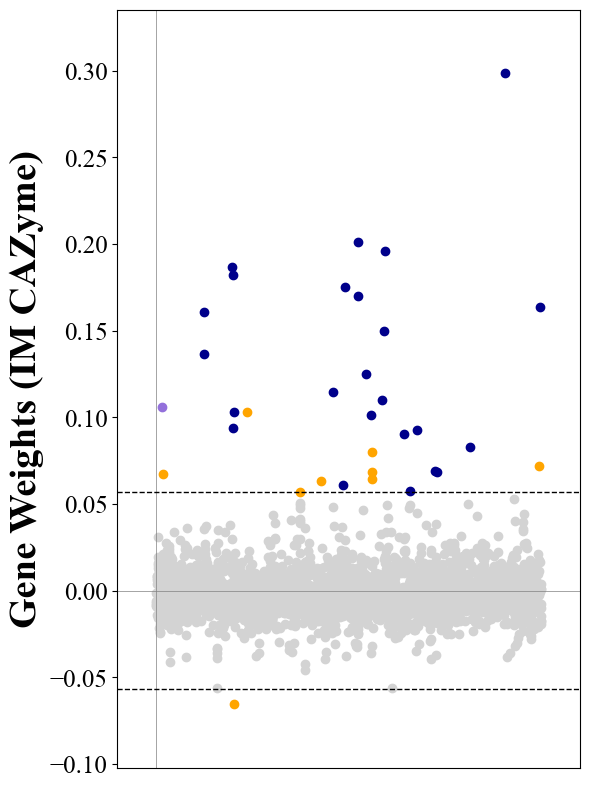

In [15]:
# Example: list of genes you want to highlight
cellulosome_genes = df_genes_gh9.loc[df_genes_gh9.category=='cellulosome'].index.to_list()
prob_cellulosome_genes = df_genes_gh9.loc[df_genes_gh9.category=='probably_cellulosome'].index.to_list()
not_cellulosome = df_genes_gh9.loc[df_genes_gh9.category=='not_cellulosome'].index.to_list()

# Create a group label per gene
groups = pd.Series('not_in_imod', index=ica_data.M.index.to_list())
groups.loc[cellulosome_genes] = 'selected'
groups.loc[prob_cellulosome_genes] = 'prob_selected'
groups.loc[not_cellulosome] = 'not_cellulosome'


# Define colors: grey for others, red for selected genes
colors = {
    'not_in_imod': 'lightgrey', #not in IM
    'not_cellulosome': 'orange', #member of IM
    "prob_selected": "mediumpurple", #probable
    "selected": "darkblue", #published

}

ax = plot_gene_weights(ica_data, imod_of_interest, by='start', 
                        groups=groups,     # which genes are in which group
                        colors=colors,     # color mapping
                        show_labels=True, adjust_labels=True, legend=False)
                    
ax.set_ylabel(f'Gene Weights (IM {imod_of_interest})', fontdict={'weight':'bold', 'size':28})
# ax.set_xlabel('Gene Start', fontdict={'weight':'bold', 'size':30})
ax.set_xlabel('')

ax.tick_params(axis='y', labelsize=18)

# ax.tick_params(axis='x', labelsize=18)

ax.tick_params(axis='x', size=0)
ax.set_xticks([])

labels_of_interest = [] #any labels that I would like to keep

for t in ax.texts:
    if t.get_text() not in labels_of_interest:
        t.remove()

# Get current figure object and modify its size
fig = plt.gcf() 
fig.set_size_inches(6, 8)

plt.tight_layout()

# save plot
# plt.savefig('./results_characterize_imodulons/gene_wts_cazymes_im.png', transparent=True, pad_inches=0.01, dpi=300, format='png')

plt.show()

#### SigI6

In [16]:
imod_of_interest = 'SigI6'

df_genes_sig16 = ica_data.view_imodulon(imod_of_interest).sort_values(by='gene_weight', ascending=False)


##### Plotting the genes associated with IM with custom categories assigned

In [17]:
# assign a new category for plot_gene_weights
df_genes_sig16['category'] = ''
unclassified_genes = list()
for gene, col in df_genes_sig16.iterrows():
    if gene in genes_of_cellulosomes:
        df_genes_sig16.loc[gene, 'category'] = 'cellulosome'
    elif gene in ['Clo1313_0522']:
        df_genes_sig16.loc[gene, 'category'] = 'probably_cellulosome'
    else: #'Clo1313_0729', 'Clo1313_1702', 'Clo1313_1703', 'Clo1313_1704', 'Clo1313_0055'
        df_genes_sig16.loc[gene, 'category'] = 'not_cellulosome'
        unclassified_genes.append(gene)
df_genes_sig16.loc[unclassified_genes]

,gene_weight,gene_name,accession,old_locus_tag,start,end,strand,gene_product,COG,uniprot,operon,GO_MF,GO_BP,InterPro,PFAMs,regulator,category
Clo1313_1605,0.141470,RS08100,CP002416.1,NaN,1874903,1875541,-,transcriptional regulator%2C TraR/DksA family,Signal transduction mechanisms,UPI000038F63E,Op1114,NaN,NaN,DnaK_N;YteA;Znf_DskA_TraR;Znf_DskA_TraR_CS;,zf-dskA_traR,NaN,not_cellulosome
Clo1313_0525,0.082930,sigI,CP002416.1,NaN,579294,580058,-,RNA polymerase%2C sigma 28 subunit%2C SigI,Transcription,UPI0000538615,Op333,NaN,NaN,RNA_pol_sigma-I;RNA_pol_sigma70_r2;RNA_pol_sig...,Sigma70_r2,NaN,not_cellulosome
Clo1313_0721,0.081711,RS03730,CP002416.1,NaN,829059,829796,+,ABC transporter related protein,Defense mechanisms,UPI0001C146BD,Op480,NaN,NaN,NaN,ABC_tran,Rex_2471,not_cellulosome
Clo1313_0972,0.076983,RS04965,CP002416.1,NaN,1131697,1133226,+,peptidase S1 and S6 chymotrypsin/Hap,"Post-translational modification, protein turno...",UPI000053167A,Op659,NaN,NaN,Chloro_Bact_Ser_Proteases;PDZ;PDZ_sf;Peptidase...,PDZ_2;Trypsin_2,NaN,not_cellulosome
Clo1313_1911,0.066428,sigI,CP002416.1,NaN,2232481,2233230,-,RNA polymerase sigma-I factor,Transcription,UPI00005351A3,Op1308,NaN,NaN,RNA_pol_sigma-I;RNA_pol_sigma70_r2;RNA_pol_sig...,Sigma70_r2,Sigma-13,not_cellulosome


<Figure size 1000x1000 with 0 Axes>

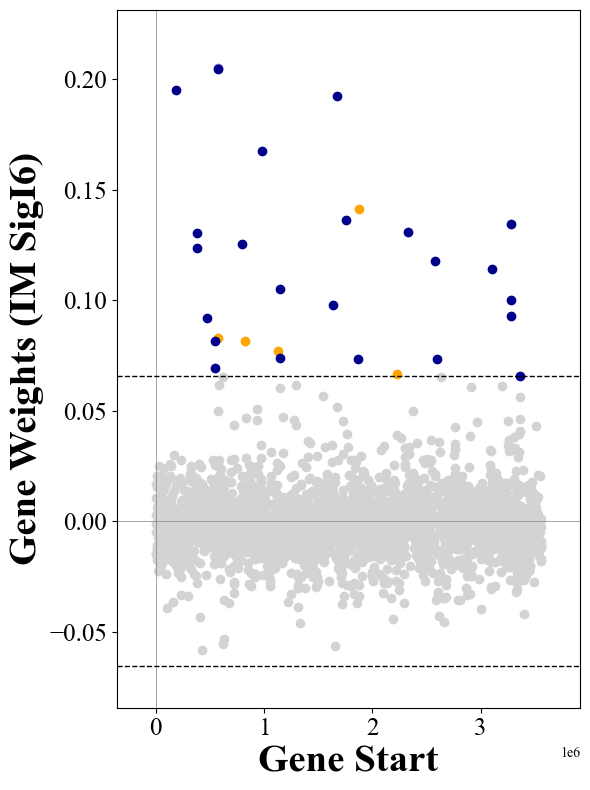

In [18]:
# Example: list of genes you want to highlight
cellulosome_genes = df_genes_sig16.loc[df_genes_sig16.category=='cellulosome'].index.to_list()
prob_cellulosome_genes = df_genes_sig16.loc[df_genes_sig16.category=='probably_cellulosome'].index.to_list()
not_cellulosome = df_genes_sig16.loc[df_genes_sig16.category=='not_cellulosome'].index.to_list()

# Create a group label per gene
groups = pd.Series('not_in_imod', index=ica_data.M.index.to_list())
groups.loc[cellulosome_genes] = 'selected'
groups.loc[prob_cellulosome_genes] = 'prob_selected'
groups.loc[not_cellulosome] = 'not_cellulosome'


# Define colors: grey for others, red for selected genes
colors = {
    'not_in_imod': 'lightgrey', #not in IM
    'not_cellulosome': 'orange', #member of IM
    "prob_selected": "mediumpurple", #probable
    "selected": "darkblue", #published

}

plt.figure(figsize=(10, 10))
ax = plot_gene_weights(ica_data, imod_of_interest, by='start', 
                        groups=groups,     # which genes are in which group
                        colors=colors,     # color mapping
                        show_labels=True, adjust_labels=True, legend=False)
                    
ax.set_ylabel(f'Gene Weights (IM {imod_of_interest})', fontdict={'weight':'bold', 'size':28})
ax.set_xlabel('Gene Start', fontdict={'weight':'bold', 'size':28})

ax.tick_params(axis='both', labelsize=18)

labels_of_interest = [] #any labels that I would like to keep

for t in ax.texts:
    if t.get_text() not in labels_of_interest:
        t.remove()

# Get current figure object and modify its size
fig = plt.gcf() 
fig.set_size_inches(6, 8)

plt.tight_layout()

# save plot
# plt.savefig('./results_characterize_imodulons/gene_wts_sigi6_im.png', transparent=True, pad_inches=0.01, dpi=300, format='png')

plt.show()

#### LexA_1449

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


Text(32.347222222222214, 0.5, 'Gene Weights')

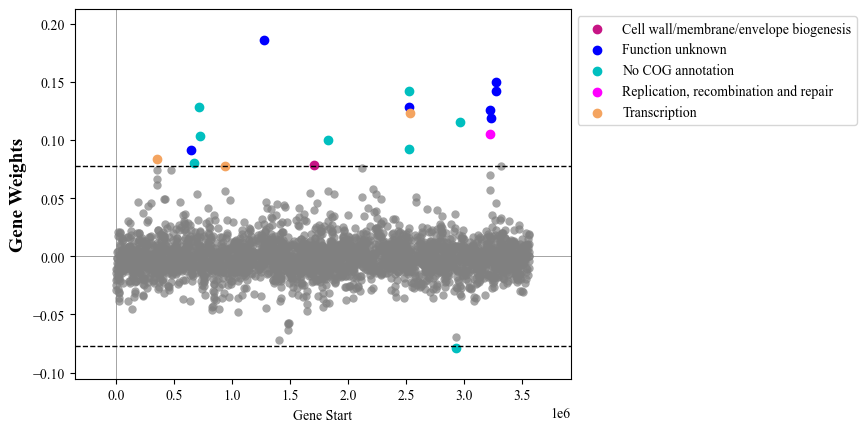

In [ ]:
imod_of_interest = 'LexA_1449'
ax = plot_gene_weights(ica_data, imod_of_interest, by='start')

labels_of_interest = list() #any labels that I would like to keep

for t in ax.texts:
    if t.get_text() not in labels_of_interest:
        t.remove()


ax.set_ylabel('Gene Weights', fontdict={'weight':'bold', 'size':14})

##### plot activity of LexA for different conditions within cell_stressor project

[]

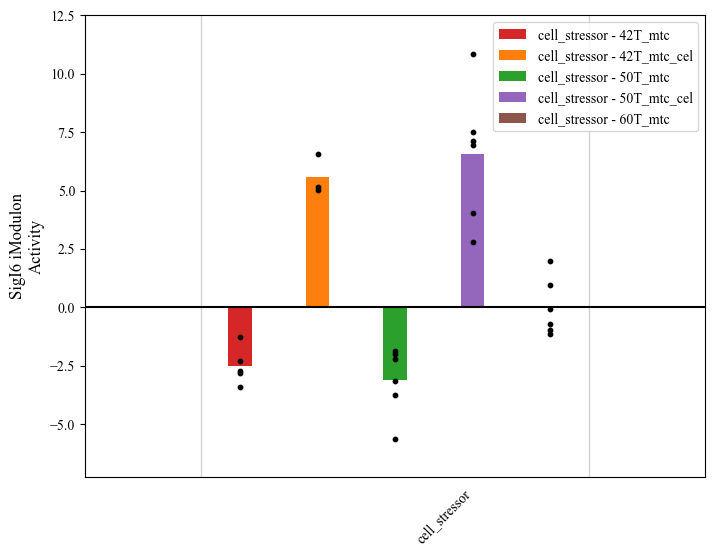

In [23]:
proj_interested = ['cell_stressor']

fig, ax = plt.subplots(figsize=(8, 6))

plot_activities(ica_data, imod_of_interest, projects=proj_interested, highlight=proj_interested, ax=ax, legend_kwargs=None)

for p in ax.patches:
    x = p.get_x() + p.get_width() / 2.0
    new_w = 0.3
    p.set_x(x - new_w / 2.0)
    p.set_width(new_w)

ax.set_xticks([])

### Plotting the normalized expression of genes of interest (e.g., dksA) for the projects of interest

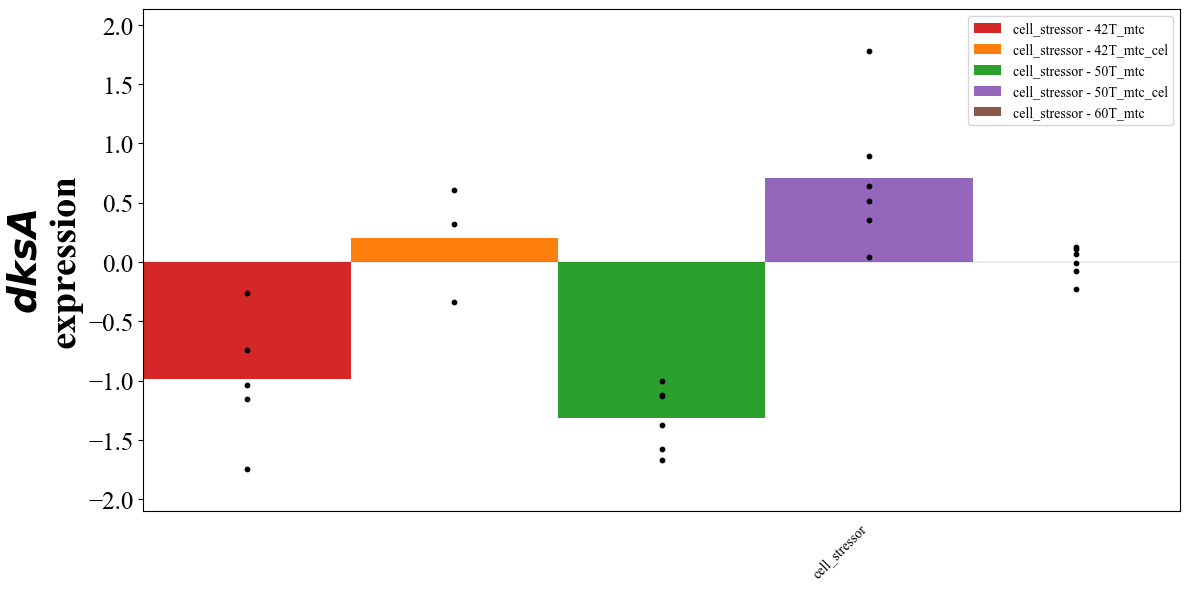

In [21]:
proj_interested = ['cell_stressor']
gene_of_interest = 'Clo1313_1605'

ax = plot_expression(ica_data, gene_of_interest, projects=proj_interested, highlight=proj_interested)

ax.set_xticks([])

ax.tick_params(axis='y', labelsize=18)

ax.set_ylabel('$\mathbfit{dksA}$\nexpression', fontdict={'weight':'bold', 'size':28})

# remove the vertical lines separating projects
# Find and remove the last LineCollection (likely the vlines)
for coll in ax.collections:
    if isinstance(coll, matplotlib.collections.LineCollection):
        coll.set_visible(False)

# # add horizontal line
ax.axhline(0, color="black", linewidth=0.1)
# remove the spaces
num_bars = len(ax.containers)
ax.set_xlim(1, num_bars)

# remove spaces between the bars
# Find bar positions and widths
xs = np.array([p.get_x() for p in ax.patches])
ws = np.array([p.get_width() for p in ax.patches])

# Make each bar span from its x to the next x (no gaps)
# Here we assume bars are ordered by x
order = np.argsort(xs)
xs_sorted = xs[order]

# Compute new width as distance to next bar (last keeps its old width)
new_ws = ws.copy()
new_ws[order[:-1]] = xs_sorted[1:] - xs_sorted[:-1]

for p, w in zip(ax.patches, new_ws):
    p.set_width(w)

# Remove margins so outer bars touch the axes
ax.margins(x=0)

        
# Get current figure object and modify its size
fig = plt.gcf() 
fig.set_size_inches(12, 6)


plt.tight_layout()

# save plot
# plt.savefig('./results_characterize_imodulons/dksa_expression_cell_stressor_proj.png', transparent=True, pad_inches=0.01, dpi=300, format='png')

plt.show()

### Comparing activities of IMs associated with cellulose deconstruction for project of interest -- lacI

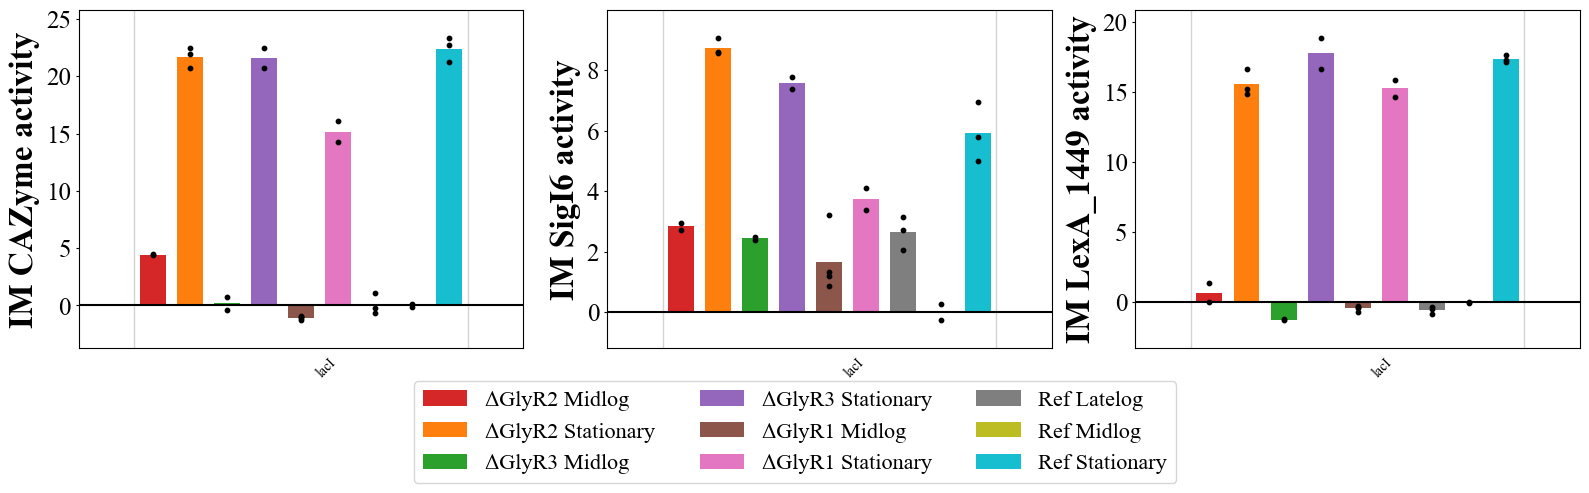

In [22]:
proj_interested = ['lacI']

fig, ax = plt.subplots(1,3, figsize=(16,4))

for i, im in enumerate(['CAZyme', 'SigI6', 'LexA_1449']):
    plot_activities(ica_data, im, projects=proj_interested, highlight=proj_interested, ax=ax[i], legend_kwargs=None)

    # Remove the legend if it was created
    leg = ax[i].get_legend()
    if leg is not None:
        leg.remove()

    for p in ax[i].patches:
        x = p.get_x() + p.get_width() / 2.0
        new_w = 0.7
        p.set_x(x - new_w / 2.0)
        p.set_width(new_w)

    ax[i].set_xticks([])

    ax[i].set_ylabel(f'IM {im} activity', fontdict={'weight':'bold', 'size':24})

    ax[i].tick_params(size=2, labelsize=18)
# legend
handles, labels = [], []
for ax in fig.axes:
    for handle, label in zip(*ax.get_legend_handles_labels()):
        handles.append(handle)
        labels.append(label)

dict_rename = {'lacI - del_hpt_del_Clo1313_0089_midlog': 'ΔGlyR2 Midlog',
 'lacI - del_hpt_del_Clo1313_0089_sta': 'ΔGlyR2 Stationary',
 'lacI - del_hpt_del_Clo1313_0396_midlog': 'ΔGlyR3 Midlog',
 'lacI - del_hpt_del_Clo1313_0396_sta': 'ΔGlyR3 Stationary',
 'lacI - del_hpt_del_Clo1313_2023_midlog': 'ΔGlyR1 Midlog',
 'lacI - del_hpt_del_Clo1313_2023_sta': 'ΔGlyR1 Stationary',
 'lacI - del_hpt_latelog': 'Ref Latelog',
 'lacI - del_hpt_midlog': 'Ref Midlog',
 'lacI - del_hpt_sta': 'Ref Stationary'}

# Filter out duplicates
by_label = dict(zip(labels, handles))

# Rebuild dictionary with new keys
by_label_renamed = {dict_rename.get(k, k): v for k, v in by_label.items()}

fig.legend(by_label_renamed.values(), by_label_renamed.keys(), bbox_to_anchor=(0.5, -0.25), loc='lower center', fontsize=16, ncol=3)


plt.tight_layout()  # Fixes overlapping elements automatically

# save plot
# plt.savefig('./results_characterize_imodulons/im_activity_laci_proj.png', bbox_inches='tight', transparent=True, pad_inches=0.1, dpi=300, format='png')

plt.show()

# FIN